## Step 0: Import Libraries
These are the Python tools we use:
- **pandas** → to read and work with the data table
- **matplotlib / seaborn** → to make graphs
- **scikit-learn** → for the prediction model

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
print("Libraries loaded successfully!")

Libraries loaded successfully!


## Step 1: Load the Data
**Before running this cell:**
1. Download the dataset from Kaggle (search: *"crop yield prediction dataset"*)
2. Extract the zip file and find **`yield_df.csv`**
3. Run the cell below and click **"Choose Files"** to upload `yield_df.csv`

In [ ]:
# Upload the file in Google Colab
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Not running in Colab - make sure yield_df.csv is in the same folder.")

df = pd.read_csv("yield_df.csv")
print("Data loaded!")

Saving yield_df.csv to yield_df.csv
Data loaded!


In [ ]:
# First 5 rows of the data
df.head()

,Unnamed: 0,Area,Item,Year,hg/ha_yield,average_rain_fall_mm_per_year,pesticides_tonnes,avg_temp
0,0,Albania,Maize,1990,36613,1485.0,121.0,16.37
1,1,Albania,Potatoes,1990,66667,1485.0,121.0,16.37
2,2,Albania,"Rice, paddy",1990,23333,1485.0,121.0,16.37
3,3,Albania,Sorghum,1990,12500,1485.0,121.0,16.37
4,4,Albania,Soybeans,1990,7000,1485.0,121.0,16.37


In [ ]:
# Size of the data
print("Number of rows   :", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows   : 28242
Number of columns: 8


In [ ]:
# Column names and data types
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 28242 entries, 0 to 28241
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Unnamed: 0                     28242 non-null  int64  
 1   Area                           28242 non-null  object 
 2   Item                           28242 non-null  object 
 3   Year                           28242 non-null  int64  
 4   hg/ha_yield                    28242 non-null  int64  
 5   average_rain_fall_mm_per_year  28242 non-null  float64
 6   pesticides_tonnes              28242 non-null  float64
 7   avg_temp                       28242 non-null  float64
dtypes: float64(3), int64(3), object(2)
memory usage: 1.7+ MB


### What the columns mean
| Column | Meaning |
|---|---|
| Area | Country name |
| Item | Crop name (Rice, Wheat, Maize, etc.) |
| Year | Year of the record |
| hg/ha_yield | Crop yield in hectograms per hectare |
| average_rain_fall_mm_per_year | Yearly rainfall (mm) |
| pesticides_tonnes | Pesticides used (tonnes) |
| avg_temp | Average temperature (°C) |

## Step 2: Clean the Data
We will:
1. Remove the extra index column (`Unnamed: 0`)
2. Give the columns short, simple names
3. Convert yield from hg/ha to **kg/ha** (easier to understand; 1 hg = 0.1 kg)
4. Remove missing values and duplicate rows

In [ ]:
# 1. Remove the extra index column if it exists
if "Unnamed: 0" in df.columns:
    df = df.drop(columns=["Unnamed: 0"])

# 2. Rename columns
df = df.rename(columns={
    "Area": "Country",
    "Item": "Crop",
    "hg/ha_yield": "Yield",
    "average_rain_fall_mm_per_year": "Rainfall",
    "pesticides_tonnes": "Pesticides",
    "avg_temp": "Temperature"
})

# 3. Convert yield to kg per hectare
df["Yield"] = df["Yield"] / 10

# 4. Remove missing values and duplicates
print("Missing values before cleaning:")
print(df.isnull().sum())
before = len(df)
df = df.dropna().drop_duplicates()
print("\nRows removed:", before - len(df))
print("Rows remaining:", len(df))

df.head()

Missing values before cleaning:
Country        0
Crop           0
Year           0
Yield          0
Rainfall       0
Pesticides     0
Temperature    0
dtype: int64

Rows removed: 2310
Rows remaining: 25932


,Country,Crop,Year,Yield,Rainfall,Pesticides,Temperature
0,Albania,Maize,1990,3661.3,1485.0,121.0,16.37
1,Albania,Potatoes,1990,6666.7,1485.0,121.0,16.37
2,Albania,"Rice, paddy",1990,2333.3,1485.0,121.0,16.37
3,Albania,Sorghum,1990,1250.0,1485.0,121.0,16.37
4,Albania,Soybeans,1990,700.0,1485.0,121.0,16.37


In [ ]:
# Basic statistics (mean, min, max, etc.)
df.describe().round(2)

,Year,Yield,Rainfall,Pesticides,Temperature
count,25932.00,25932.00,25932.00,25932.00,25932.00
mean,2001.56,7697.81,1146.84,34782.57,20.42
std,7.06,8464.76,717.39,57228.57,6.44
min,1990.00,5.00,51.00,0.04,1.30
25%,1995.00,1999.60,593.00,1597.00,16.58
50%,2001.00,3953.00,1083.00,15373.00,21.42
75%,2008.00,10416.80,1668.00,45620.00,26.06
max,2013.00,50141.20,3240.00,367778.00,30.65


In [ ]:
# Which crops are in the data?
print("Crops in dataset:")
print(df["Crop"].value_counts())

Crops in dataset:
Crop
Potatoes                3956
Maize                   3824
Wheat                   3539
Rice, paddy             3091
Soybeans                2940
Sorghum                 2770
Sweet potatoes          2593
Cassava                 1889
Yams                     774
Plantains and others     556
Name: count, dtype: int64


## Step 3: Graphs (Exploratory Data Analysis)
This is the most important part of the project. After each graph, write what you observe in the **Observation** box.

### Graph 1: Average Yield Over the Years

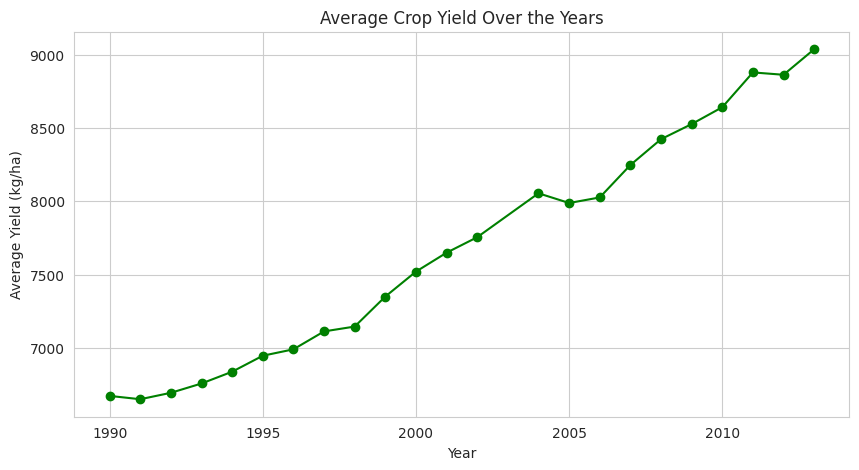

In [ ]:
yearly = df.groupby("Year")["Yield"].mean()

plt.plot(yearly.index, yearly.values, marker="o", color="green")
plt.title("Average Crop Yield Over the Years")
plt.xlabel("Year")
plt.ylabel("Average Yield (kg/ha)")
plt.show()

### Graph 2: Average Yield of Each Crop

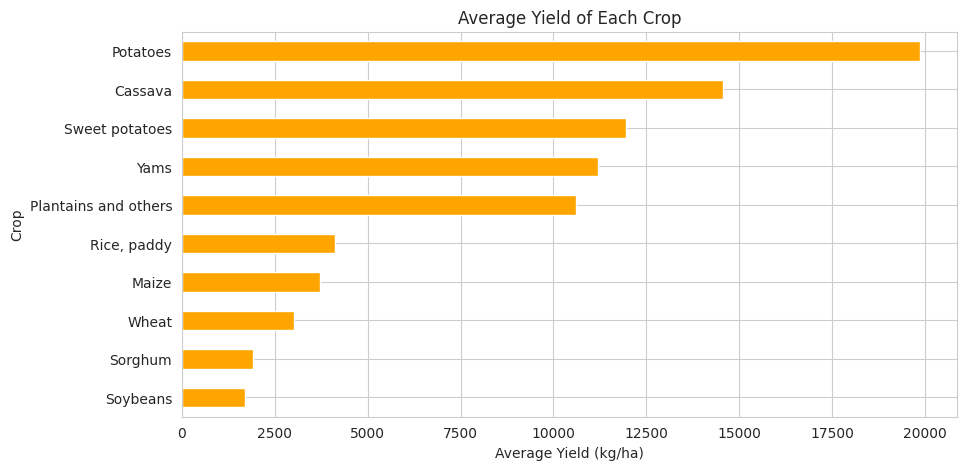

In [ ]:
crop_yield = df.groupby("Crop")["Yield"].mean().sort_values()

crop_yield.plot(kind="barh", color="orange")
plt.title("Average Yield of Each Crop")
plt.xlabel("Average Yield (kg/ha)")
plt.ylabel("Crop")
plt.show()

### Graph 3: Rainfall vs Yield

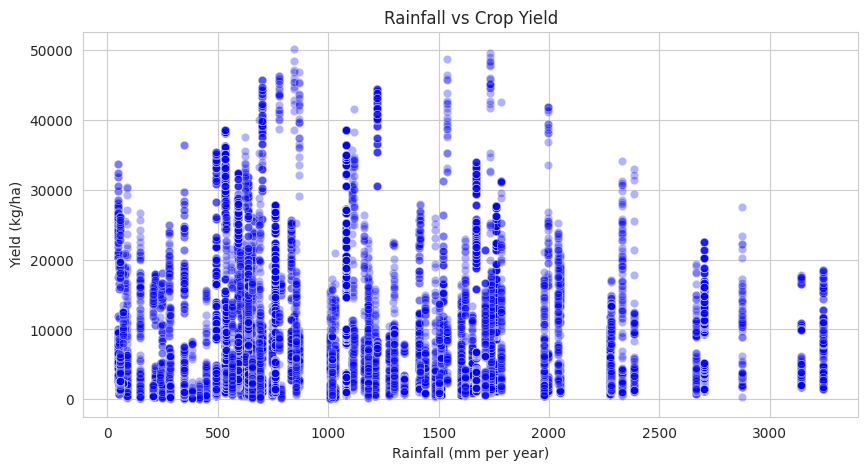

In [ ]:
sns.scatterplot(data=df, x="Rainfall", y="Yield", alpha=0.3, color="blue")
plt.title("Rainfall vs Crop Yield")
plt.xlabel("Rainfall (mm per year)")
plt.ylabel("Yield (kg/ha)")
plt.show()

### Graph 4: Temperature vs Yield

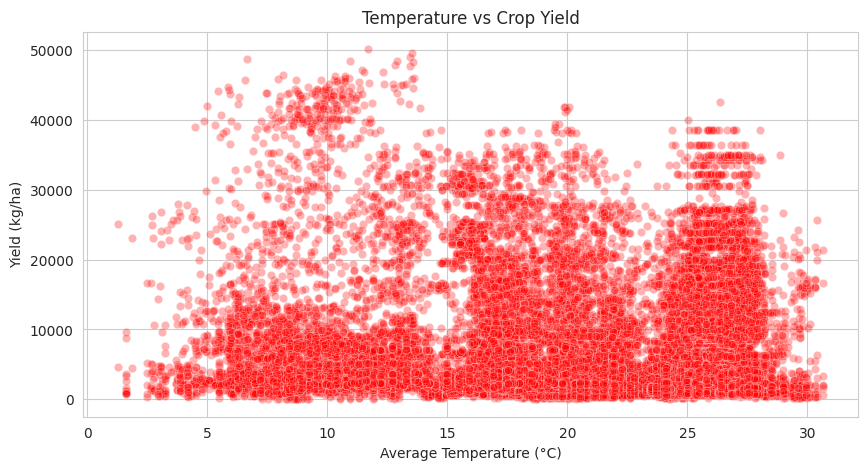

In [ ]:
sns.scatterplot(data=df, x="Temperature", y="Yield", alpha=0.3, color="red")
plt.title("Temperature vs Crop Yield")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Yield (kg/ha)")
plt.show()

### Graph 5: Rainfall vs Yield for One Crop (Rice)
Different crops behave differently, so let's look at just one crop. You can change `"Rice, paddy"` to any crop name from the list above.

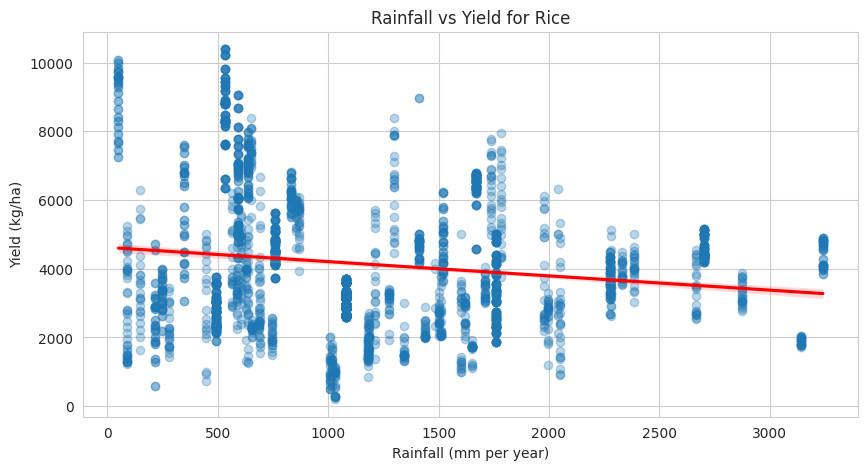

In [ ]:
one_crop = df[df["Crop"] == "Rice, paddy"]

sns.regplot(data=one_crop, x="Rainfall", y="Yield",
            scatter_kws={"alpha": 0.3}, line_kws={"color": "red"})
plt.title("Rainfall vs Yield for Rice")
plt.xlabel("Rainfall (mm per year)")
plt.ylabel("Yield (kg/ha)")
plt.show()

### Graph 6: Correlation Heatmap
Correlation shows how strongly two things are related:
- Close to **+1** → both increase together
- Close to **−1** → one increases, the other decreases
- Close to **0** → no clear relation

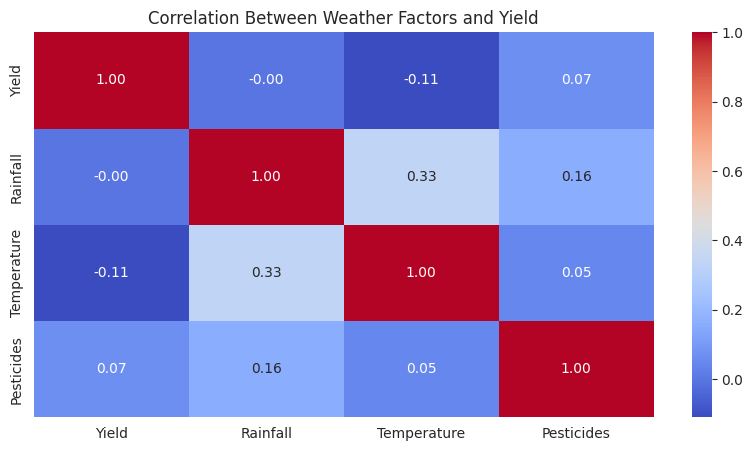

In [ ]:
corr = df[["Yield", "Rainfall", "Temperature", "Pesticides"]].corr()

sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Weather Factors and Yield")
plt.show()

## Step 4: Predict Yield using Linear Regression
**Linear Regression** draws the best straight-line relationship between the inputs and the output.

- **Inputs (X):** Rainfall, Temperature
- **Output (y):** Yield

We use 80% of the data to **train** the model and 20% to **test** it.

In [ ]:
# Model 1: using only weather
X = df[["Rainfall", "Temperature"]]
y = df["Yield"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model1 = LinearRegression()
model1.fit(X_train, y_train)
pred1 = model1.predict(X_test)

print("Model 1 (Weather only)")
print("R² Score :", round(r2_score(y_test, pred1), 3))
print("MAE      :", round(mean_absolute_error(y_test, pred1), 2), "kg/ha")

Model 1 (Weather only)
R² Score : 0.013
MAE      : 6420.65 kg/ha


**How to read the results:**
- **R² Score** → between 0 and 1. Closer to 1 = better prediction.
- **MAE (Mean Absolute Error)** → on average, how far our prediction is from the real value.

The R² score here will be **low**. Because yield depends a lot on **which crop** it is (potatoes give far more kg/ha than wheat). Weather alone can't explain that. So let's add the crop type.

In [ ]:
# Model 2: weather + crop type
# get_dummies converts crop names into 0/1 columns so the model can use them
X2 = pd.get_dummies(df[["Rainfall", "Temperature", "Crop"]], columns=["Crop"])
y2 = df["Yield"]

X2_train, X2_test, y2_train, y2_test = train_test_split(X2, y2, test_size=0.2, random_state=42)

model2 = LinearRegression()
model2.fit(X2_train, y2_train)
pred2 = model2.predict(X2_test)

print("Model 2 (Weather + Crop type)")
print("R² Score :", round(r2_score(y2_test, pred2), 3))
print("MAE      :", round(mean_absolute_error(y2_test, pred2), 2), "kg/ha")

Model 2 (Weather + Crop type)
R² Score : 0.627
MAE      : 3223.72 kg/ha


### Comparing the Two Models

In [ ]:
results = pd.DataFrame({
    "Model": ["Weather only", "Weather + Crop"],
    "R² Score": [round(r2_score(y_test, pred1), 3), round(r2_score(y2_test, pred2), 3)],
    "MAE (kg/ha)": [round(mean_absolute_error(y_test, pred1), 2),
                    round(mean_absolute_error(y2_test, pred2), 2)]
})
results

,Model,R² Score,MAE (kg/ha)
0,Weather only,0.013,6420.65
1,Weather + Crop,0.627,3223.72


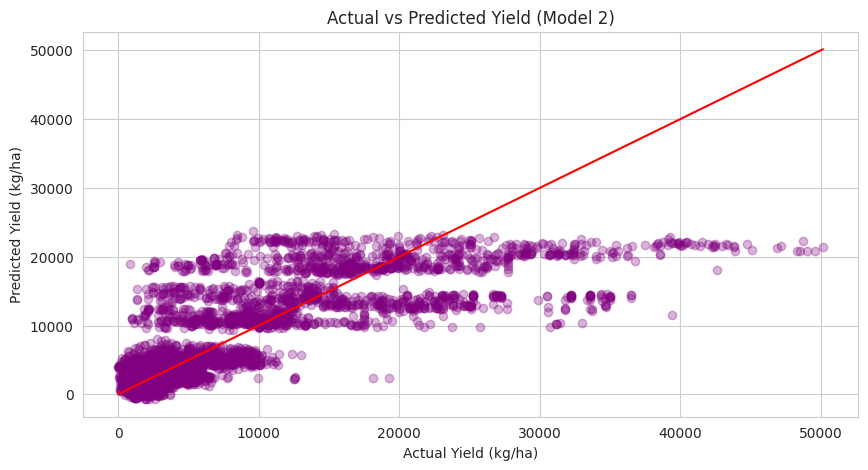

In [ ]:
# Actual vs Predicted graph for Model 2
plt.scatter(y2_test, pred2, alpha=0.3, color="purple")
plt.plot([y2_test.min(), y2_test.max()], [y2_test.min(), y2_test.max()], color="red")
plt.title("Actual vs Predicted Yield (Model 2)")
plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.show()

### Try Your Own Prediction
Change the values below and run the cell.

In [ ]:
crop_name   = "Rice, paddy"   # pick a crop from the list above
rainfall    = 1200            # mm per year
temperature = 26              # °C

new_data = pd.DataFrame(0, index=[0], columns=X2.columns)
new_data["Rainfall"] = rainfall
new_data["Temperature"] = temperature
new_data["Crop_" + crop_name] = 1

result = model2.predict(new_data)[0]
print(f"Crop        : {crop_name}")
print(f"Rainfall    : {rainfall} mm")
print(f"Temperature : {temperature} °C")
print(f"Predicted Yield: {result:.2f} kg/ha")

Crop        : Rice, paddy
Rainfall    : 1200 mm
Temperature : 26 °C
Predicted Yield: 3108.95 kg/ha


Random Forest Regression

Cell 1: Import Required Libraries

This cell imports the necessary Python libraries for building and evaluating the Random Forest Regression model. Pandas is used for data manipulation, Matplotlib for visualization, and Scikit-learn provides tools for data splitting, preprocessing, model training, and performance evaluation.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

Cell 2: Inspect the Dataset

This cell examines the dataset to understand its structure, features, and data types. It helps verify that the dataset contains the required columns, such as rainfall, temperature, pesticides, crop, country, year, and crop yield.

In [ ]:
print(df.head())
print("\nDataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

   Country         Crop  Year   Yield  Rainfall  Pesticides  Temperature
0  Albania        Maize  1990  3661.3    1485.0       121.0        16.37
1  Albania     Potatoes  1990  6666.7    1485.0       121.0        16.37
2  Albania  Rice, paddy  1990  2333.3    1485.0       121.0        16.37
3  Albania      Sorghum  1990  1250.0    1485.0       121.0        16.37
4  Albania     Soybeans  1990   700.0    1485.0       121.0        16.37

Dataset shape: (25932, 7)

Column names:
['Country', 'Crop', 'Year', 'Yield', 'Rainfall', 'Pesticides', 'Temperature']


Cell 3: Select Features and Target Variable

This cell selects the independent variables used to predict crop yield. The features include rainfall, temperature, pesticide usage, crop type, country, and year. The target variable is Yield, which represents the crop yield that the model will learn to predict.

In [ ]:
features = [
    "Rainfall",
    "Temperature",
    "Pesticides",
    "Crop",
    "Country",
    "Year"
]

X = df[features]
y = df["Yield"]

print("Input features:")
print(X.head())

print("\nTarget variable:")
print(y.head())

Input features:
   Rainfall  Temperature  Pesticides         Crop  Country  Year
0    1485.0        16.37       121.0        Maize  Albania  1990
1    1485.0        16.37       121.0     Potatoes  Albania  1990
2    1485.0        16.37       121.0  Rice, paddy  Albania  1990
3    1485.0        16.37       121.0      Sorghum  Albania  1990
4    1485.0        16.37       121.0     Soybeans  Albania  1990

Target variable:
0    3661.3
1    6666.7
2    2333.3
3    1250.0
4     700.0
Name: Yield, dtype: float64


Cell 4: Preprocess and Split the Data

This cell converts categorical variables, such as crop type and country, into numerical values using One-Hot Encoding. Numerical features are passed through without additional transformation. The dataset is then divided into training data (80%) and testing data (20%) to evaluate the model on unseen observations.

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            ["Crop", "Country"]
        ),
        (
            "numerical",
            "passthrough",
            ["Rainfall", "Temperature", "Pesticides", "Year"]
        )
    ]
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 20745
Testing samples: 5187


Cell 5: Create the Random Forest Model

This cell creates a Random Forest Regression pipeline. Random Forest combines predictions from multiple decision trees to produce a final prediction. The model uses 300 trees, and the preprocessing steps are included in the pipeline so that the same transformations are applied during training and prediction.

In [ ]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            RandomForestRegressor(
                n_estimators=300,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest model created successfully.")

Random Forest model created successfully.


Cell 6: Train the Model

This cell trains the Random Forest Regression model using the training dataset. The model learns relationships between weather conditions, pesticide usage, crop type, country, year, and crop yield.

In [ ]:
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


Cell 7: Predict Crop Yield

This cell uses the trained Random Forest model to predict crop yields for the test dataset. These predictions are compared with the actual yields to measure the model's performance.

In [ ]:
rf_predictions = rf_model.predict(X_test)

print("First 10 actual yields:")
print(y_test.iloc[:10].values)

print("\nFirst 10 predicted yields:")
print(rf_predictions[:10])

First 10 actual yields:
[15578.2  1578.7  7261.4  3077.4  2808.5  1335.  15399.7  4809.2  2511.2
 36796.9]

First 10 predicted yields:
[12925.03366667  1568.52933333  7438.73333333  1964.41066667
  2837.85        1371.75666667 16166.63633333  8497.425
  3458.82466667 22720.841     ]


Cell 8: Evaluate Model Performance

This cell calculates three evaluation metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE), and the R² score. MAE measures the average absolute prediction error, RMSE gives greater weight to larger errors, and R² indicates how well the model explains variation in crop yield.

In [ ]:
rf_mae = mean_absolute_error(y_test, rf_predictions)

rf_rmse = np.sqrt(
    mean_squared_error(y_test, rf_predictions)
)

rf_r2 = r2_score(y_test, rf_predictions)

print("Random Forest Regression Results")
print("--------------------------------")
print(f"MAE  : {rf_mae:.2f} kg/ha")
print(f"RMSE : {rf_rmse:.2f} kg/ha")
print(f"R²   : {rf_r2:.4f}")

Random Forest Regression Results
--------------------------------
MAE  : 403.12 kg/ha
RMSE : 1066.91 kg/ha
R²   : 0.9843


Cell 9: Visualize Actual vs. Predicted Yield

This cell creates a scatter plot comparing actual crop yields with the values predicted by the Random Forest model. Points closer to the diagonal reference line indicate more accurate predictions.

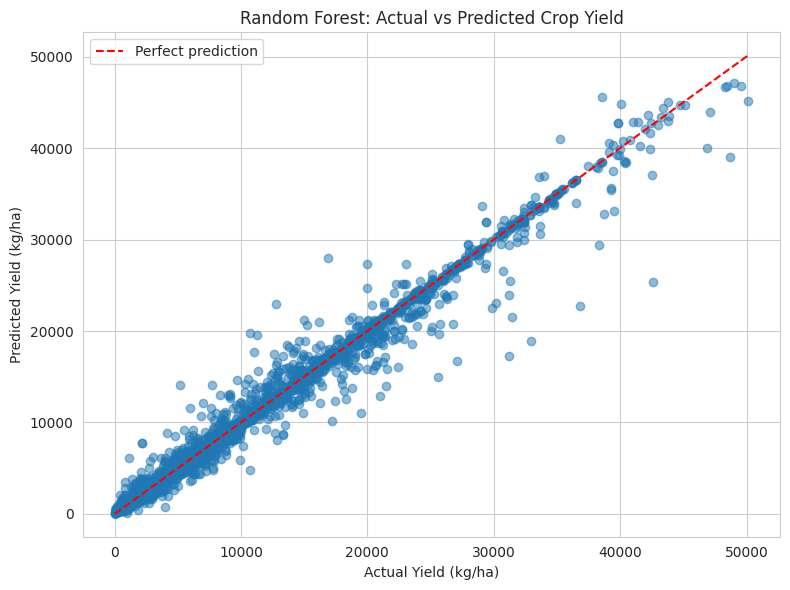

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    rf_predictions,
    alpha=0.5
)

min_val = min(y_test.min(), rf_predictions.min())
max_val = max(y_test.max(), rf_predictions.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--",
    label="Perfect prediction"
)

plt.xlabel("Actual Yield (kg/ha)")
plt.ylabel("Predicted Yield (kg/ha)")
plt.title("Random Forest: Actual vs Predicted Crop Yield")
plt.legend()
plt.tight_layout()
plt.show()

Cell 10: Display Prediction Results

This cell creates a DataFrame containing actual crop yields, predicted crop yields, and absolute prediction errors. It makes it easier to inspect individual predictions and identify observations where the model produces larger errors.

In [ ]:
rf_results = pd.DataFrame({
    "Actual Yield": y_test.values,
    "Predicted Yield": rf_predictions
})

rf_results["Absolute Error"] = abs(
    rf_results["Actual Yield"] -
    rf_results["Predicted Yield"]
)

print(rf_results.head(10))

   Actual Yield  Predicted Yield  Absolute Error
0       15578.2     12925.033667     2653.166333
1        1578.7      1568.529333       10.170667
2        7261.4      7438.733333      177.333333
3        3077.4      1964.410667     1112.989333
4        2808.5      2837.850000       29.350000
5        1335.0      1371.756667       36.756667
6       15399.7     16166.636333      766.936333
7        4809.2      8497.425000     3688.225000
8        2511.2      3458.824667      947.624667
9       36796.9     22720.841000    14076.059000


Model Performance Comparison
               Algorithm       MAE  R2 Score
       Linear Regression 3223.7180    0.6270
Random Forest Regression  403.1183    0.9843

Model with lower MAE: Random Forest Regression


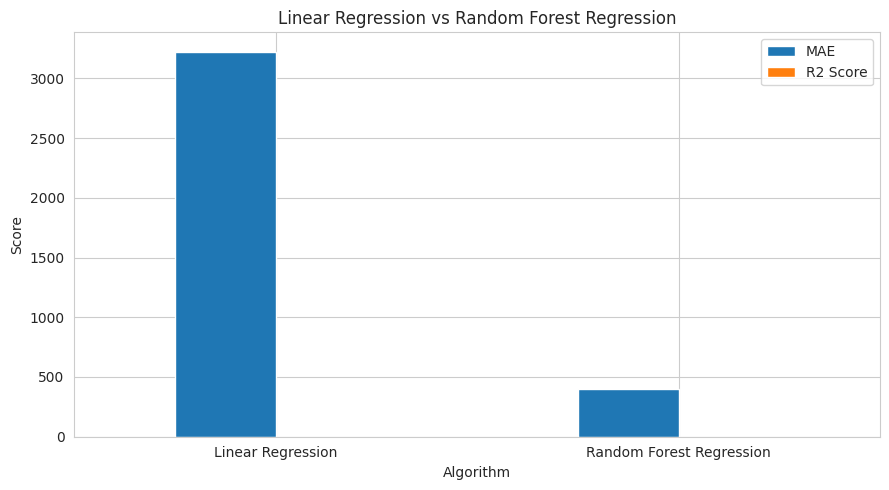

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Linear Regression predictions
linear_predictions = model2.predict(
    pd.get_dummies(
        X_test[["Rainfall", "Temperature", "Crop"]],
        columns=["Crop"]
    ).reindex(columns=X2.columns, fill_value=0)
)

# Random Forest predictions are already stored in rf_predictions

# Calculate performance metrics
comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Random Forest Regression"
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

# Display comparison
print("Model Performance Comparison")
print("============================")
print(comparison.round(4).to_string(index=False))

# Find the model with lower MAE
best_model = comparison.loc[
    comparison["MAE"].idxmin(), "Algorithm"
]
print(f"\nModel with lower MAE: {best_model}")

# Plot comparison
comparison.set_index("Algorithm")[["MAE", "R2 Score"]].plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Linear Regression vs Random Forest Regression")
plt.ylabel("Score")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Decision Tree Algorithm

Cell 1: Import Required Libraries

This cell imports the Python libraries required to build, train, evaluate, and visualize the Decision Tree Regression model. Scikit-learn provides the Decision Tree algorithm, preprocessing tools, data-splitting functions, and evaluation metrics.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

Cell 2: Select Features and Target Variable

This cell selects rainfall, temperature, pesticide usage, crop type, country, and year as input features. The Yield column is selected as the target variable. The model uses these inputs to learn patterns associated with crop yield.

In [ ]:
features = [
    "Rainfall",
    "Temperature",
    "Pesticides",
    "Crop",
    "Country",
    "Year"
]

X = df[features]
y = df["Yield"]

Cell 3: Encode Categorical Features

This cell uses One-Hot Encoding to convert the categorical features Crop and Country into numerical representations. The numerical features are passed through unchanged so they can be used by the Decision Tree model.

In [ ]:
categorical_features = ["Crop", "Country"]

numeric_features = [
    "Rainfall",
    "Temperature",
    "Pesticides",
    "Year"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        ("numeric", "passthrough", numeric_features)
    ]
)

Cell 4: Split the Dataset

This cell divides the dataset into training and testing subsets. The model learns from 80% of the observations and is evaluated on the remaining 20%. Setting random_state=42 makes the split reproducible when the data and code remain unchanged.

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (20745, 6)
Testing data: (5187, 6)


Cell 5: Create the Decision Tree Model

This cell initializes a Decision Tree Regressor inside a preprocessing pipeline. The tree learns a series of decision rules by splitting the data into smaller groups. Parameters such as max_depth, min_samples_split, and min_samples_leaf limit tree complexity and can help reduce overfitting.

In [ ]:
dt_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "regressor",
            DecisionTreeRegressor(
                max_depth=15,
                min_samples_split=5,
                min_samples_leaf=2,
                random_state=42
            )
        )
    ]
)

Cell 6: Train the Model

This cell trains the Decision Tree Regression model on the training data. The tree identifies feature-based splits that help predict crop yield from the available weather, agricultural, geographical, and year-related information.

In [ ]:
dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully!")

Decision Tree model trained successfully!


Cell 7: Predict Crop Yield

This cell generates crop yield predictions for the test dataset using the trained Decision Tree model. The predicted values can then be compared with actual crop yields to assess prediction accuracy.

In [ ]:
dt_predictions = dt_model.predict(X_test)

print("First 10 actual yields:")
print(y_test.head(10).to_list())

print("\nFirst 10 predicted yields:")
print(dt_predictions[:10])

First 10 actual yields:
[15578.2, 1578.7, 7261.4, 3077.4, 2808.5, 1335.0, 15399.7, 4809.2, 2511.2, 36796.9]

First 10 predicted yields:
[10207.15         967.03061574  6846.90416667  1198.15819672
  3309.39490446  2818.75207668 17068.42488152  5168.13529412
  3865.         17068.42488152]


Cell 8: Evaluate Model Performance

This cell calculates MAE, RMSE, and R² to evaluate the Decision Tree model. Lower MAE and RMSE values generally indicate smaller prediction errors, while a higher R² score generally indicates that the model explains more of the variation in crop yield.

In [ ]:
dt_mae = mean_absolute_error(y_test, dt_predictions)

dt_rmse = mean_squared_error(
    y_test,
    dt_predictions
) ** 0.5

dt_r2 = r2_score(y_test, dt_predictions)

print("Decision Tree Regression Results")
print("--------------------------------")
print(f"MAE:  {dt_mae:.4f}")
print(f"RMSE: {dt_rmse:.4f}")
print(f"R² Score: {dt_r2:.4f}")

Decision Tree Regression Results
--------------------------------
MAE:  755.3827
RMSE: 1601.7390
R² Score: 0.9646


cell 9: Visualize Actual vs. Predicted Yield

This cell generates a scatter plot of actual and predicted crop yields. The diagonal reference line represents perfect predictions. The distance between each point and the line indicates how far a prediction is from its actual value.

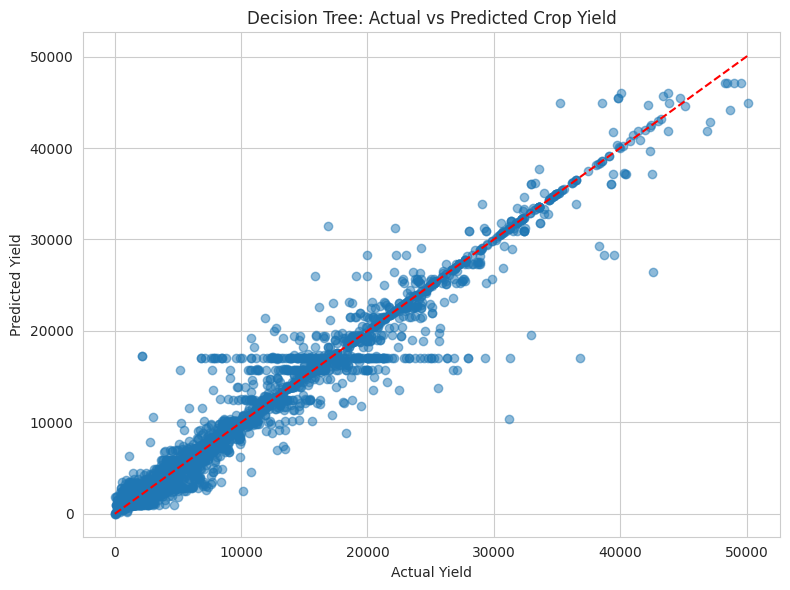

In [ ]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    dt_predictions,
    alpha=0.5
)

min_value = min(y_test.min(), dt_predictions.min())
max_value = max(y_test.max(), dt_predictions.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    "r--"
)

plt.xlabel("Actual Yield")
plt.ylabel("Predicted Yield")
plt.title("Decision Tree: Actual vs Predicted Crop Yield")
plt.tight_layout()
plt.show()

Cell 10: Display Prediction Results

This cell organizes the actual yields, predicted yields, and absolute errors into a DataFrame. This helps analyze individual predictions and understand where the Decision Tree model performs well or produces larger errors.

In [ ]:
dt_results = pd.DataFrame({
    "Actual Yield": y_test.to_numpy(),
    "Predicted Yield": dt_predictions
})

dt_results["Absolute Error"] = (
    dt_results["Actual Yield"] -
    dt_results["Predicted Yield"]
).abs()

print(dt_results.head(10))

   Actual Yield  Predicted Yield  Absolute Error
0       15578.2     10207.150000     5371.050000
1        1578.7       967.030616      611.669384
2        7261.4      6846.904167      414.495833
3        3077.4      1198.158197     1879.241803
4        2808.5      3309.394904      500.894904
5        1335.0      2818.752077     1483.752077
6       15399.7     17068.424882     1668.724882
7        4809.2      5168.135294      358.935294
8        2511.2      3865.000000     1353.800000
9       36796.9     17068.424882    19728.475118


Comparison of the Three Algorithms

In [ ]:
comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        dt_mae,
        mean_absolute_error(y_test, rf_predictions)
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        dt_r2,
        r2_score(y_test, rf_predictions)
    ]
})

print(comparison.round(4).to_string(index=False))

        Algorithm       MAE  R2 Score
Linear Regression 3223.7180    0.6270
    Decision Tree  755.3827    0.9646
    Random Forest  403.1183    0.9843


This cell compares the performance of Linear Regression, Decision Tree Regression, and Random Forest Regression using MAE, RMSE, and R². The comparison helps identify which algorithm predicts crop yield more accurately on the test dataset. The model with the lowest MAE and RMSE and the highest R² is generally preferred, provided all three models are evaluated on the same test observations.

Model Performance Comparison
        Algorithm       MAE      RMSE  R2 Score
Linear Regression 3223.7180 5199.2019    0.6270
    Decision Tree  755.3827 1601.7390    0.9646
    Random Forest  403.1183 1066.9078    0.9843

Best model based on lowest MAE: Random Forest


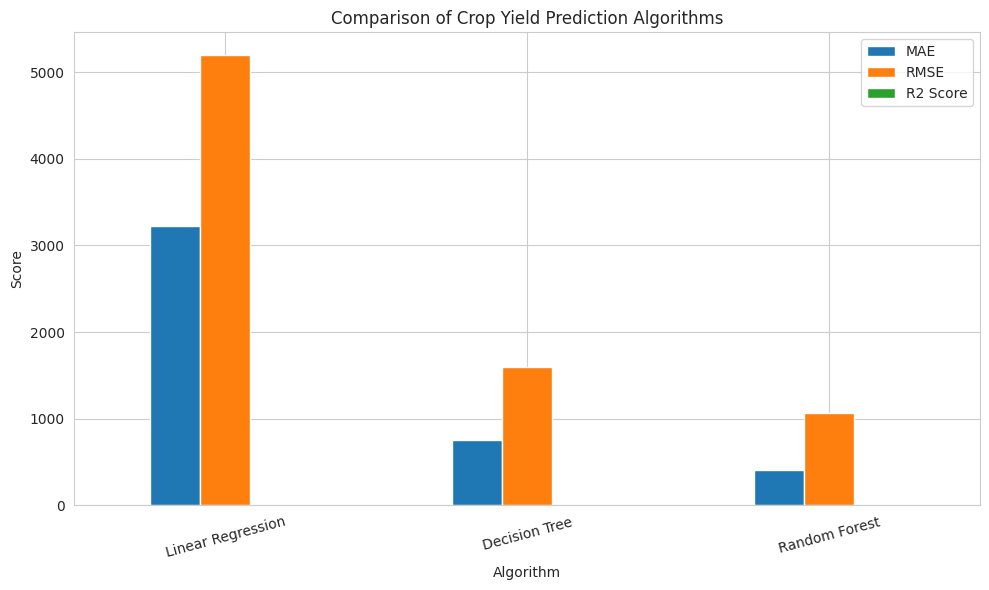

In [ ]:

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import pandas as pd
import matplotlib.pyplot as plt

# Decision Tree predictions
dt_predictions = dt_model.predict(X_test)

# Random Forest predictions
rf_predictions = rf_model.predict(X_test)

# Linear Regression predictions
# Use the features and encoding expected by model2
linear_X_test = pd.get_dummies(
    X_test[["Rainfall", "Temperature", "Crop"]],
    columns=["Crop"]
).reindex(columns=X2.columns, fill_value=0)

linear_predictions = model2.predict(linear_X_test)

# Compare all three algorithms
comparison = pd.DataFrame({
    "Algorithm": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [
        mean_absolute_error(y_test, linear_predictions),
        mean_absolute_error(y_test, dt_predictions),
        mean_absolute_error(y_test, rf_predictions)
    ],
    "RMSE": [
        mean_squared_error(y_test, linear_predictions) ** 0.5,
        mean_squared_error(y_test, dt_predictions) ** 0.5,
        mean_squared_error(y_test, rf_predictions) ** 0.5
    ],
    "R2 Score": [
        r2_score(y_test, linear_predictions),
        r2_score(y_test, dt_predictions),
        r2_score(y_test, rf_predictions)
    ]
})

print("Model Performance Comparison")
print("============================")
print(comparison.round(4).to_string(index=False))

# Best model based on MAE
best_model = comparison.loc[comparison["MAE"].idxmin(), "Algorithm"]
print(f"\nBest model based on lowest MAE: {best_model}")

# Plot comparison
comparison.set_index("Algorithm")[["MAE", "RMSE", "R2 Score"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Comparison of Crop Yield Prediction Algorithms")
plt.ylabel("Score")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


Conclusion :
The crop yield prediction project evaluates three machine learning algorithms: Linear Regression, Decision Tree Regression, and Random Forest Regression. Their performance is compared using MAE, RMSE, and R². These metrics help determine how closely the predicted crop yields match the actual yields. The best-performing model will be selected based on the evaluation results. This analysis demonstrates how weather conditions, pesticide usage, crop type, geographical location, and year can be used as features for crop yield prediction.